# MMELON Model Inference

Run inference with a finetuned MMELON model on **any CSV file** containing SMILES strings.

## Steps
0. Configuration — edit paths here
1. Preview input data
2. Load model
3. Build DataLoader
4. Run inference
5. Inspect predictions
6. Evaluate (if labels available)
7. Enrichment metrics (Precision@K / EF@K)
8. Top hits

## 0. Configuration

**Edit the paths below before running.**

In [1]:
IN_COLAB=False
import os
import torch
run_on_wdr91 = False

model_name = "mmelon" #????????????
USER=os.getenv("USER")
if run_on_wdr91:
    # set inference model
    DATA_NAME = "wdr91"
    # MODEL_PATH = "/proj/ligand_ai/models/wdr91_ASMS_train_val_v1/mmelon_10_seed1234/last-v3.ckpt"
    MODEL_PATH = "michalozeryflato/biomed.sm.mv-te-84m.wdr91_asms"
    
    # set datapath
    if IN_COLAB:
        DATA_PATH = "/content/wdr91_test.csv"
    else:
        DATA_PATH = "/proj/ligand_ai/datasets_manager/processed/splits/wdr91_ASMS_train_val_v1/test.csv"
else:
    DATA_NAME = "pgk2"
    
    # MODEL_PATH = "/proj/ligand_ai/models/PGK2_DEL_cdd_to_creative/mmelon_50/last.ckpt"
    # MODEL_PATH="michalozeryflato/biomed.sm.mv-te-84m.pgk2_del_cdd"
    MODEL_PATH=f"/home/jupyter/repos/mmelon/biomed-multi-view/model/pgk2_del_cdd/last.ckpt"
    
    if IN_COLAB:
        DATA_PATH = "/content/del_creative.csv"
    else:
        DATA_PATH =f"/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/ASMS_PGK2_allNegatives.csv"
        #DATA_PATH =f"/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/pgk2_test.csv"

assert os.path.exists(DATA_PATH),  f"Data not found:  {DATA_PATH}"

DATA_DIR_FOR_MMELON =None if IN_COLAB else f"/proj/ligand_ai/users/{USER}/"
# Column names
SMILES_COLUMN = "smiles"
LABEL_COLUMN = "label"

if IN_COLAB:
    OUTPUT_DIR_PATH = f"/content/results"
else:
    OUTPUT_DIR_PATH = f"/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/mmelon-pgk2" 

OUTPUT_PATH = os.path.join(OUTPUT_DIR_PATH, f"{DATA_NAME}_{model_name}_predictions.csv")
os.makedirs(os.path.dirname(OUTPUT_PATH) or ".", exist_ok=True)

# Inference settings
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print(f"{MODEL_PATH=}")
print(f"{DATA_PATH=}")
print(f"{OUTPUT_PATH=}")
print(f"{DEVICE=}")

MODEL_PATH='/home/jupyter/repos/mmelon/biomed-multi-view/model/pgk2_del_cdd/last.ckpt'
DATA_PATH='/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/ASMS_PGK2_allNegatives.csv'
OUTPUT_PATH='/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/mmelon-pgk2/pgk2_mmelon_predictions.csv'
DEVICE='cuda'


## 1. Preview Input Data

In [2]:
import pandas as pd

input_df = pd.read_csv(DATA_PATH)
input_df["sample_id"] = input_df.index.astype(str)  # Add sample_id column based on index
display(input_df)

,smiles,label,sample_id
0,O=c1nc(NCc2ccc(OC3CCCC3)cc2)[nH]c2[nH]ncc12,1,0
1,COc1ccsc1S(=O)(=O)N1C(C(=O)O)CC2CCCCC21,1,1
2,COc1ccc(-c2nsc(NC(=O)c3cccc4cn[nH]c34)n2)cc1,1,2
3,Cc1cc(N2CCCC(Nc3ncnc4cc(Cl)ccc34)C2)n(C)n1,1,3
4,CC1CN(c2nc(-c3ccc(Cl)s3)nc3c2CCC3)CCC1O,1,4
...,...,...,...
460157,NC(=O)C(OC(=O)c1ccc2c(c1)OCCCO2)c1ccccc1,0,460157
460158,COc1ccccc1-c1cc(COC(=O)c2cc(C)c(C)c(S(N)(=O)=O...,0,460158
460159,CCn1c(SCC(=O)Nc2cc(C(C)(C)C)no2)nnc1C1CC1,0,460159
460160,Cc1nc(COc2ccc(Cl)cc2)sc1C(=O)OC(C)C(=O)NC1CC1,0,460160


## 2. Load Model

In [3]:
from bmfm_sm.predictive.modules.finetune_lightning_module import FineTuneLightningModule

if os.path.exists(MODEL_PATH):
    model_path = MODEL_PATH
else:
    from huggingface_hub import hf_hub_download
    model_path = hf_hub_download(
                repo_id=MODEL_PATH,
                filename="last.ckpt",
                revision="main",
            )
model = FineTuneLightningModule.load_from_checkpoint(
        model_path, 
        map_location=DEVICE
    )
model.to(DEVICE)

2026-03-17 17:33:11,219 - root - INFO - instance-20260302-162623:140589568976704:0:0 - Initializing model with params {'agg_arch': 'coeff_mlp', 'agg_gate_input': 'coeff_mlp', 'agg_weight_freeze': None, 'inference_mode': False}
2026-03-17 17:33:11,838 - rdkit - INFO - instance-20260302-162623:140589568976704:0:0 - Enabling RDKit 2022.09.5 jupyter extensions
/opt/conda/envs/biomed-multiview/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/envs/biomed-multiview/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
2026-03-17 17:33:13,167 - root - INFO - instance-20260302-162623:140589568976704:0:0 - U

FineTuneLightningModule(
  (model): SmallMoleculeMultiView(
    (model_graph): Graph2dModel(
      (graph_encoder): Graph2dEncoder(
        (dropout_module): Dropout(p=0.0, inplace=False)
        (graph_feature): GraphFeatureTokenizer(
          (atom_encoder): Embedding(4608, 512, padding_idx=0)
          (edge_encoder): Embedding(1536, 512, padding_idx=0)
          (graph_token): Embedding(1, 512)
          (null_token): Embedding(1, 512)
          (lap_encoder): Linear(in_features=32, out_features=512, bias=False)
          (lap_eig_dropout): Dropout2d(p=0.2, inplace=False)
          (order_encoder): Embedding(2, 512)
        )
        (emb_layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (final_layer_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
        (layers): ModuleList(
          (0-11): 12 x Graph2dEncoderLayer(
            (dropout_module): Dropout(p=0.0, inplace=False)
            (self_attn): MultiheadAttention(
              (atten

## 3. Build DataLoader

In [4]:
import os
import shutil
from torch.utils.data import DataLoader
from bmfm_sm.predictive.data_modules.multimodal_finetune_dataset import MultiModalFinetuneDataPipeline
from bmfm_sm.core.data_modules.namespace import TaskType

def create_dataloader(
    csv_path: str,
    smiles_column: str = 'smiles',
    label_column: str = 'label',
    batch_size: int = 32,
    num_workers: int = 0,  # Set to 0 to avoid multiprocessing issues in notebooks
    data_dir: str = None,
):
    print(f"Creating DataLoader from: {csv_path}")

    # Get the directory containing the CSV file
    data_dir = data_dir or os.path.dirname(csv_path)
    data_dir=f"/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test"
    print(data_dir)
    predict_csv = os.path.join(data_dir, 'data_predict.csv')
    print(predict_csv)
    shutil.copy(csv_path, predict_csv)

    # Dataset arguments for MMELON framework (matching evaluate_mmelon.py lines 448-455)
    dataset_args = {
        'task_type': TaskType.CLASSIFICATION,
        'num_tasks': 1,
        'modalities': ['TEXT_MODEL', 'IMAGE_MODEL', 'GRAPH_2D_MODEL'],
        'smiles_col': smiles_column,
        'label_cols': [label_column],
        'split_col': None
    }
    
    # Create dataset (matching evaluate_mmelon.py lines 458-462)
    dataset = MultiModalFinetuneDataPipeline(
        data_dir=data_dir,
        dataset_args=dataset_args,
        stage='predict'  # Use 'predict' stage like evaluate_mmelon.py
    )

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        collate_fn=dataset.collate_fn
    )
        
    return dataloader

In [5]:
dataloader = create_dataloader(
    csv_path=DATA_PATH,
    smiles_column=SMILES_COLUMN,
    label_column=LABEL_COLUMN,
    batch_size= 32, #128, #32
    num_workers=4,
    data_dir=DATA_DIR_FOR_MMELON,
)

2026-03-17 17:33:13,733 - root - INFO - instance-20260302-162623:140589568976704:0:0 - Working on task TaskType.CLASSIFICATION
2026-03-17 17:33:13,734 - root - INFO - instance-20260302-162623:140589568976704:0:0 - modalities running in data pipeline TEXT_MODEL,IMAGE_MODEL,GRAPH_2D_MODEL


Creating DataLoader from: /home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/ASMS_PGK2_allNegatives.csv
/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test
/home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/data_predict.csv


In [6]:
## inspect first batch
first_batch = next(iter(dataloader))
for k,v in first_batch.items():
    if isinstance(v, torch.Tensor):
        print(f"{k}: {type(v)=} {v.shape=}")
    else:
        print(f"{k}: {type(v)=} {len(v)=}")

img: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([32, 3, 224, 224])
label: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([32, 1])
smiles.tokenized: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([32, 50])
attention_mask: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([32, 50])
node_num: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([32])
node_data: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([755, 9])
edge_num: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([32])
edge_data: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([1668, 5])
edge_index: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([2, 1668])
lap_eigvec: type(v)=<class 'torch.Tensor'> v.shape=torch.Size([755, 29])


## 4. Run Inference

In [7]:
import numpy as np
from tqdm import tqdm
def run_inference(
    model,
    dataloader: DataLoader,
    device: str = 'cuda',
) -> pd.DataFrame:
    
    all_preds = []
    all_probs = []
    
    model.eval()
    batch_count = 0
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="batches"):
            # Move batch to device
            for key in batch:
                if isinstance(batch[key], torch.Tensor):
                    batch[key] = batch[key].to(device)
            
            # Forward pass - use forward0 to get embeddings (same as evaluate_mmelon.py line 486)
            embeddings = model.model.forward0(batch)
            if isinstance(embeddings, tuple):
                embeddings = embeddings[0]  # Extract embeddings from tuple
            
            # Apply prediction head (same as evaluate_mmelon.py line 491)
            logits = model.pred_head(embeddings)
            
            # Squeeze extra dimensions if present
            if logits.dim() > 2:
                logits = logits.squeeze(-1)
            
            # Get probabilities - use sigmoid for binary classification (line 494)
            probs = torch.sigmoid(logits).cpu().numpy()
            preds = (probs > 0.5).astype(int)
            
            all_probs.append(probs)
            all_preds.append(preds)
            batch_count += 1
    
    # Concatenate and flatten (same as evaluate_mmelon.py lines 500-501)
    probabilities = np.vstack(all_probs).flatten()
    predictions = np.vstack(all_preds).flatten()
    
    return pd.DataFrame({"predicted_label": predictions, "prediction_score": probabilities})

In [8]:
%%time
predictions_df = run_inference(model, dataloader, device=DEVICE)
display(predictions_df)

2026-03-17 17:33:17,511 - root - INFO - instance-20260302-162623:140589568976704:0:0 - in train False setting deterministic_eval = True
batches: 100%|██████████| 14381/14381 [41:03<00:00,  5.84it/s] 


,predicted_label,prediction_score
0,0,0.035671
1,0,0.001844
2,0,0.023032
3,0,0.007970
4,0,0.006904
...,...,...
460157,0,0.004058
460158,0,0.002362
460159,0,0.002548
460160,0,0.002253


CPU times: user 18min 31s, sys: 1min 44s, total: 20min 16s
Wall time: 41min 3s


In [9]:
predictions_df.to_csv(OUTPUT_PATH, index=False)
print("wrote", OUTPUT_PATH)

wrote /home/jupyter/repos/mmelon/biomed-multi-view/ASMS-test/mmelon-pgk2/pgk2_mmelon_predictions.csv


## 5. Inspect Predictions

In [10]:
predictions_df = pd.concat([input_df, predictions_df], axis=1)

In [11]:
predictions_df = predictions_df.rename(columns={LABEL_COLUMN: "true_label" })
display(predictions_df)

,smiles,true_label,sample_id,predicted_label,prediction_score
0,O=c1nc(NCc2ccc(OC3CCCC3)cc2)[nH]c2[nH]ncc12,1,0,0,0.035671
1,COc1ccsc1S(=O)(=O)N1C(C(=O)O)CC2CCCCC21,1,1,0,0.001844
2,COc1ccc(-c2nsc(NC(=O)c3cccc4cn[nH]c34)n2)cc1,1,2,0,0.023032
3,Cc1cc(N2CCCC(Nc3ncnc4cc(Cl)ccc34)C2)n(C)n1,1,3,0,0.007970
4,CC1CN(c2nc(-c3ccc(Cl)s3)nc3c2CCC3)CCC1O,1,4,0,0.006904
...,...,...,...,...,...
460157,NC(=O)C(OC(=O)c1ccc2c(c1)OCCCO2)c1ccccc1,0,460157,0,0.004058
460158,COc1ccccc1-c1cc(COC(=O)c2cc(C)c(C)c(S(N)(=O)=O...,0,460158,0,0.002362
460159,CCn1c(SCC(=O)Nc2cc(C(C)(C)C)no2)nnc1C1CC1,0,460159,0,0.002548
460160,Cc1nc(COc2ccc(Cl)cc2)sc1C(=O)OC(C)C(=O)NC1CC1,0,460160,0,0.002253


In [12]:
print(f"Shape: {predictions_df.shape}")
print(f"\nPredicted label distribution:")
print(predictions_df["predicted_label"].value_counts().sort_index())
print(f"\nScore statistics:")
print(predictions_df["prediction_score"].describe())

Shape: (460162, 5)

Predicted label distribution:
predicted_label
0    460020
1       142
Name: count, dtype: int64

Score statistics:
count    460162.000000
mean          0.006941
std           0.019845
min           0.001226
25%           0.002604
50%           0.003534
75%           0.005660
max           0.988330
Name: prediction_score, dtype: float64


## 6. Evaluate (if labels available)

CLASSIFICATION METRICS
Accuracy  : 0.9963
Precision : 0.0141
Recall    : 0.0013
F1 Score  : 0.0023
ROC AUC   : 0.7878
PR AUC    : 0.0151


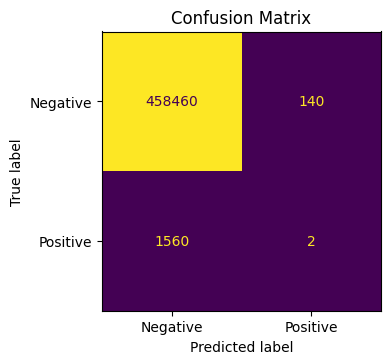

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

has_labels = predictions_df["true_label"].notna().any()

if has_labels:
    valid   = predictions_df[predictions_df["true_label"].notna()].copy()
    y_true  = valid["true_label"].astype(int)
    y_pred  = valid["predicted_label"].astype(int)
    y_score = valid["prediction_score"].astype(float)

    print("=" * 50)
    print("CLASSIFICATION METRICS")
    print("=" * 50)
    print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision : {precision_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"Recall    : {recall_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"F1 Score  : {f1_score(y_true, y_pred, zero_division=0):.4f}")
    print(f"ROC AUC   : {roc_auc_score(y_true, y_score):.4f}")
    print(f"PR AUC    : {average_precision_score(y_true, y_score):.4f}")

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(ax=ax, colorbar=False)
    ax.set_title("Confusion Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("No true labels found — skipping evaluation.")

## 7. Enrichment Metrics (Precision@K / EF@K)

In [14]:
def calculate_enrichment_metrics(
    y_true,
    y_scores,
    top_k_values: list[int] | None = None,
) -> dict:
    if top_k_values is None:
        top_k_values = [10, 50, 100, 500, 1000, 2000]

    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    sorted_indices = np.argsort(y_scores)[::-1]
    sorted_labels = y_true[sorted_indices]

    hit_prevalence = np.sum(y_true) / len(y_true)

    enrichment: dict = {}
    for k in top_k_values:
        if k <= len(sorted_labels):
            top_k_labels = sorted_labels[:k]
            precision_at_k = np.sum(top_k_labels) / k
            enrichment[f"Precision@{k}"] = precision_at_k
            enrichment[f"EF@{k}"] = (
                precision_at_k / hit_prevalence if hit_prevalence > 0 else np.nan
            )
        else:
            enrichment[f"Precision@{k}"] = np.nan
            enrichment[f"EF@{k}"] = np.nan

    return enrichment

In [15]:
import numpy as np

n_total = len(valid)
top_k_values = sorted({k for k in [10, 50, 100, 200, 500, 1000, 2000] if k <= n_total})
if n_total not in top_k_values:
    top_k_values.append(n_total)

enrichment = calculate_enrichment_metrics(
    y_true.values, y_score.values, top_k_values=top_k_values
)

n_positives = int(y_true.sum())
hit_prev    = n_positives / n_total

print("=" * 60)
print("ENRICHMENT METRICS")
print("=" * 60)
print(f"Dataset : {n_total} compounds  |  Positives: {n_positives}  |  Hit rate: {hit_prev:.2%}")
print()
print(f"{'K':>8}  {'Precision@K':>12}  {'EF@K':>8}  {'Hits in top-K':>14}")
print("-" * 50)
for k in top_k_values:
    prec = enrichment.get(f"Precision@{k}", np.nan)
    ef   = enrichment.get(f"EF@{k}",        np.nan)
    hits = int(round(prec * k)) if not np.isnan(prec) else "N/A"
    print(f"{k:>8}  {prec:>12.4f}  {ef:>8.2f}  {hits:>14}")
print("=" * 60)

ef_rows = [
    {
        "K":             k,
        "Precision@K":   enrichment.get(f"Precision@{k}", np.nan),
        "EF@K":          enrichment.get(f"EF@{k}",        np.nan),
        "Hits_in_top_K": int(round(enrichment.get(f"Precision@{k}", 0) * k)),
    }
    for k in top_k_values
]
ef_df = pd.DataFrame(ef_rows)
ef_df


ENRICHMENT METRICS
Dataset : 460162 compounds  |  Positives: 1562  |  Hit rate: 0.34%

       K   Precision@K      EF@K   Hits in top-K
--------------------------------------------------
      10        0.0000      0.00               0
      50        0.0200      5.89               1
     100        0.0200      5.89               2
     200        0.0100      2.95               2
     500        0.0260      7.66              13
    1000        0.0380     11.19              38
    2000        0.0370     10.90              74
  460162        0.0034      1.00            1562


,K,Precision@K,EF@K,Hits_in_top_K
0,10,0.000000,0.000000,0
1,50,0.020000,5.891959,1
2,100,0.020000,5.891959,2
3,200,0.010000,2.945980,2
4,500,0.026000,7.659547,13
5,1000,0.038000,11.194722,38
6,2000,0.037000,10.900124,74
7,460162,0.003394,1.000000,1562


## 8. Top Hits

In [16]:
top_k = 10
top_predictions_df = (
    predictions_df
    .sort_values("prediction_score", ascending=False)
    .head(top_k)
    .reset_index(drop=True)
)

n_pos = (top_predictions_df["true_label"] == 1).sum()
print(f"Top {top_k} predicted positives (out of {n_pos} total predicted positives):")
display(top_predictions_df[["sample_id", SMILES_COLUMN, "prediction_score", "true_label"]])

Top 10 predicted positives (out of 0 total predicted positives):


,sample_id,smiles,prediction_score,true_label
0,41880,O=c1c(Oc2ccccc2)coc2cc(O)ccc12,0.988330,0
1,9550,COc1ccccc1Oc1coc2cc(O)ccc2c1=O,0.987502,0
2,9548,O=c1c(Oc2ccccc2Br)coc2cc(O)ccc12,0.987456,0
3,37114,O=C(NCC1CCCC1NC(=O)c1ccc2[nH]ncc2c1)c1ccc2[nH]...,0.987381,0
4,42296,Cc1oc2cc(O)ccc2c(=O)c1Oc1ccccc1Br,0.982226,0
5,21390,Cc1oc2c(C)c(O)ccc2c(=O)c1-c1ccc2ccccc2n1,0.971373,0
6,26294,Cc1c(O)ccc2c(=O)c(-c3ccc4ccccc4n3)coc12,0.970150,0
7,431247,COc1ccc(-c2cn3cc(Cl)ccc3n2)cc1OC.[Br],0.968960,0
8,298993,Cc1cc(-c2ccc(O)cc2O)nc2cc3c(cc12)OCO3.[Cl],0.965313,0
9,58445,O=c1c(Oc2ccc(Cl)cc2)coc2cc(O)ccc12,0.964836,0
